# Notebook to produce camera ready plots for Cardinality Estimation Paper

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import json

import random
from matplotlib import ticker
import math
from pathlib import Path

import matplotlib as mpl
from cycler import cycler

In [31]:
#which methods to plot
#methods = ['GNCE', 'LMKG', 'wj', 'cset']
methods = ['wj', 'sumrdf', 'cset']
methods_labels = ['Wanderjoin', 'SumRDF', 'CSET']

In [32]:
# The dataset to plot for 
dataset = "swdf_star"
# The query type
query_type = "star"
# Optional, currently not used
tag = ""

# Whether to exclude all predictions with value >= 0
exclude_invalid = False

In [33]:
exclude_1_tp_queries = False

In [34]:
# Flag whether to save the plots
save_plots = False

In [35]:
# dicts to hold ground truths, predictions and sizes of the queries
gts_dict = {}
preds_dict = {}
sizes_dict = {}
results_dir = Path("/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/benchmarks/gcare/results")

In [36]:
for method in methods:
    if not method == 'lss':
        gts = np.load(results_dir / f"{query_type}/{dataset}/{method}/gts.npy")
        preds = np.load(results_dir / f"{query_type}/{dataset}/{method}/preds.npy")
        sizes = np.load(results_dir / f"{query_type}/{dataset}/{method}/sizes.npy")
        sizes = sizes[:len(gts)]
    else:
        gts = np.load(results_dir / f"{query_type}/{dataset}/{method}/gts.npy")
        gts = 2**gts
        preds = np.load(results_dir / f"{query_type}/{dataset}/{method}/preds.npy")
        preds = 2 ** preds
        sizes = np.load(results_dir / f"{query_type}/{dataset}/{method}/sizes.npy")
    print(preds.mean()) 
    if exclude_invalid:
        valid_indices = preds > 0
        gts = gts[valid_indices]
        preds = preds[valid_indices]
        sizes = sizes[valid_indices]
    
    if exclude_1_tp_queries:
        valid_size_indices = sizes > 1
        gts = gts[valid_size_indices]
        preds = preds[valid_size_indices]
        sizes = sizes[valid_size_indices]
        
    gts_dict[method] = gts
    preds_dict[method] = preds
    sizes_dict[method] = sizes

7.92518008396341
0.2327175444727007
15.366608243130372
1123.6091559022273
50.9262745098039


In [37]:
# Defining functions for barplots based on true cardinality, based on number of triple patterns 
# defining function for calculating q-error or mae 

def barplot(gts, preds):
    Q_Errors = []
    for bin_ in Bins:
        gts_bin =  np.array(gts[(gts > bin_[0]) & (gts < bin_[1])])
        preds_bin =  np.array(preds[(gts > bin_[0]) & (gts < bin_[1])])
        preds_bin = np.round(preds_bin)
        preds_bin[np.where(preds_bin==0)] = 1
        preds_bin[np.where(preds_bin==-1)] = 1

        #q_error = np.mean(np.maximum(gts_bin/ preds_bin, preds_bin/gts_bin))
        q_error = np.mean(q_errorf(gts_bin, preds_bin, rounded=True))
        Q_Errors.append(q_error)
    return Q_Errors

def barplot_mae(gts, preds):
    Q_Errors = []
    for bin_ in Bins:
        gts_bin =  np.array(gts[(gts > bin_[0]) & (gts < bin_[1])])
        preds_bin =  np.array(preds[(gts > bin_[0]) & (gts < bin_[1])])
        q_error = np.mean(np.abs(gts_bin - preds_bin))
        Q_Errors.append(q_error)
    return Q_Errors

def q_errorf(gts, preds, mode="q", rounded=True):
    if rounded:
        preds = np.round(preds)
    preds[np.where(preds==0)] = 1
    if mode=="mae":
        return np.abs(gts-preds)
    else:
        return np.maximum(gts/ np.abs(preds), np.abs(preds)/gts)
    
def q_error(gts, preds, rounded=False):
    if rounded:
        preds = np.round(preds)
    preds[np.where(preds==0)] = 1
    return np.mean(np.maximum(gts/ np.abs(preds), np.abs(preds)/gts))


def q_error(gts, preds, mode="q", rounded=False, overunder=False):
    '''
    qError Function for the boxplots
    '''
    if rounded:
        preds = np.abs(np.round(preds))
    preds = np.abs(preds)
    preds[np.where(preds==0)] = 1
    preds[np.where(preds==-1)] = 1

    if mode=="mae":
        return np.abs(gts-preds)
    else:
        if overunder:
            return np.where(preds>gts, preds/gts, -gts/preds)
        else:
            return np.maximum(gts/ preds, preds/gts)
        
def barplot_size(gts, preds, sizes):
    Q_Errors = []
    for bin_ in Bins:
        gts_bin =  np.array(gts[sizes==bin_])
        preds_bin =  np.array(preds[sizes==bin_])
        preds_bin = np.round(preds_bin)
        preds_bin[np.where(preds_bin==0)] = 1
        preds_bin[np.where(preds_bin==-1)] = 1

        #q_error = np.mean(np.maximum(gts_bin/ preds_bin, preds_bin/gts_bin))
        q_error = np.mean(q_errorf(gts_bin, preds_bin, rounded=False))
        Q_Errors.append(q_error)
    return Q_Errors

#### Barplots against true cardinalities

In [38]:
# The bins to use for barplots against true cardinalities
Bins = [(1, 5**1), (5**1, 5**2), (5**2, 5**3),(5**3, 5**4),(5**4, 5**5),(5**5, 5**6),(5**6, 5**9) ]


In [39]:
# Creating Barplot Data
barplots_cardinality_data = {}
for method in methods:
    barplots_cardinality_data[method] = barplot(gts_dict[method], preds_dict[method])

/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3860: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:144: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [40]:
barplots_cardinality_data

{'wj': [np.float64(3.1172839506172836),
  np.float64(12.891414141414142),
  np.float64(49.15651135005973),
  np.float64(186.3823157614092),
  np.float64(nan),
  np.float64(4712.5),
  np.float64(nan)],
 'sumrdf': [np.float64(2.888888888888889),
  np.float64(14.277777777777779),
  np.float64(51.01984126984127),
  np.float64(221.69444444444446),
  np.float64(nan),
  np.float64(4712.5),
  np.float64(nan)],
 'cset': [np.float64(3.57716049382716),
  np.float64(11.502104377104377),
  np.float64(37.58529138457454),
  np.float64(132.69211355452677),
  np.float64(nan),
  np.float64(563.1122448979592),
  np.float64(nan)],
 'jsub': [np.float64(2.824074074074074),
  np.float64(14.277777777777779),
  np.float64(61.888888888888886),
  np.float64(303.22685185185185),
  np.float64(nan),
  np.float64(4712.5),
  np.float64(nan)],
 'impr': [np.float64(2.888888888888889),
  np.float64(14.277777777777779),
  np.float64(61.888888888888886),
  np.float64(218.39033942558746),
  np.float64(nan),
  np.float64(47

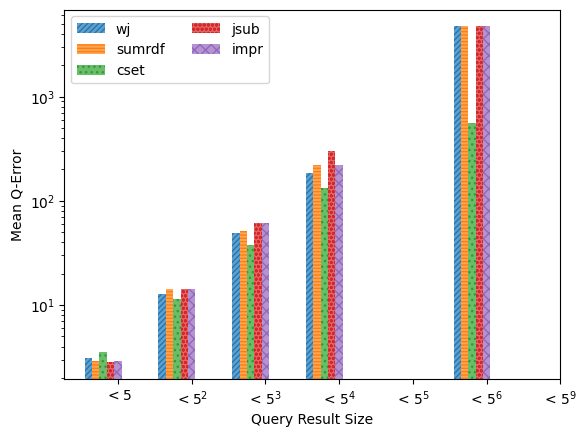

In [41]:
#plt.style.use('grayscale')

bar_cycle = (cycler('hatch', ['//////', '-----', '...','oooo', 'xxx','**', 'OOO', '\\\\']))
styles = bar_cycle()

colormap = mpl.cm.tab10.colors


data = list(barplots_cardinality_data.values())
labels = methods

X_Axis = np.arange(len(data[0]))


for i in range(len(data)):
    hatch_color = list(colormap[i])
    plt.rcParams['hatch.color'] = colormap[i]
    plt.bar(X_Axis - 0.4 + 0.1*i,data[i], 0.1, label=labels[i], color=colormap[i], alpha=0.7, **next(styles))



#plt.ylim(1, 11**5)

plt.yscale("log")

plt.legend(ncol=2)
plt.xticks(X_Axis, ["$< 5$", "$< 5^2$", "< $5^3$", "< $5^4$", "< $5^5$", "< $5^6$", "< $5^9$"])
#plt.xticks(X_Axis, ["$< 5$", "$< 5^2$", "< $5^3$", "< $5^4$", "< $5^5$", "< $5^9$"])

plt.xlabel("Query Result Size")
plt.ylabel("Mean Q-Error")
if save_plots:
    print(f"Saving Cardinality Barplot")
    plt.savefig(f"plots/{dataset}_{query_type}_barplot_card.pdf")

#### Boxplots for the methods

In [42]:
# Whether to plot boxplots for MAE or for qError
mode = "q"
# Whether to round the predictions before calculating qError
rounded = True
# Whether to plot over-and underestimation or only the simple qerror
overunder= True

In [43]:
colormap = mpl.cm.tab10.colors

In [44]:
# Creating data for the boxplots
# Creating Barplot Data
boxplot_data = {}
for method in methods:
    boxplot_data[method] = q_error(gts_dict[method], preds_dict[method],
                                   mode=mode, rounded=rounded, overunder=overunder)

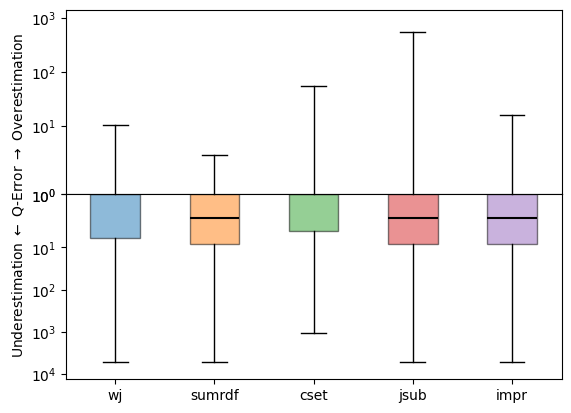

In [45]:
from matplotlib import ticker
import math


data = list(boxplot_data.values())


fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)
fig.subplots_adjust(hspace=0.0)

medianprops = dict(color="black",linewidth=1.5)

bplot1 = ax1.boxplot(data, whis=(0,100), sym="", patch_artist=True,medianprops=medianprops)
bplot2 = ax2.boxplot(data, whis=(0,100), sym="", patch_artist=True, medianprops=medianprops)


colors = ['pink', 'lightblue', 'lightgreen', 'lightgreen', 'lightgreen', 'lightgreen', 'lightgreen']
for bplot in (bplot1, bplot2):
    for patch, color in zip(bplot['boxes'], colormap):
        patch.set_facecolor(color)
        patch.set_alpha(0.5)

@ticker.FuncFormatter
def major_formatter(x, pos):
    label = "$10^{"+str(int(math.log10(abs(x))))+"}$" if x!=0 else ""
    return label


plt.yscale("symlog")
ax1.set_yscale("symlog")
ax = plt.gca()
ax1.set_ylim(bottom=1)
ax2.set_ylim(top=-1)


ax1.yaxis.set_major_formatter(major_formatter)
ax2.yaxis.set_major_formatter(major_formatter)

plt.xticks(list(range(1, len(methods) + 1)),methods)

ax2.set_ylabel(r'Underestimation $\leftarrow$ Q-Error $\rightarrow$ Overestimation')
ax2.yaxis.set_label_coords(x = -0.08, y= 1)

if save_plots:
    print(f"Saving Boxplot")
    plt.savefig(f"plots/{dataset}_{query_type}_boxplot.pdf")


#### Barplots against Query Size

In [46]:
Bins = [2,3,5, 8]

In [47]:
# Creating Barplot Data
barplots_size_data = {}
for method in methods:
    print(method)
    barplots_size_data[method] = barplot_size(gts_dict[method], preds_dict[method], sizes_dict[method][:len(gts_dict[method])])

wj
sumrdf
cset
jsub
impr


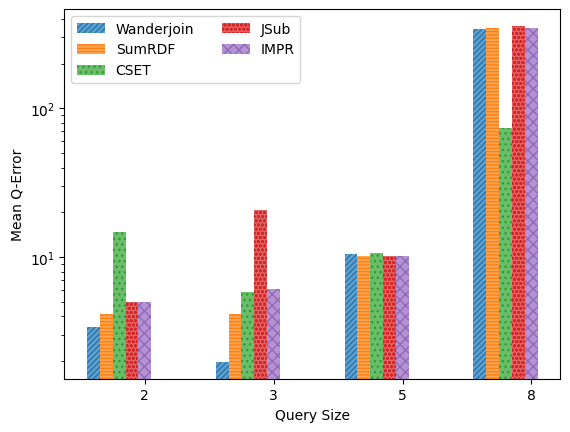

In [48]:

#plt.style.use('grayscale')

bar_cycle = (cycler('hatch', ['//////', '-----', '...','oooo', 'xxx','**', 'OOO', '\\\\']))
styles = bar_cycle()

colormap = mpl.cm.tab10.colors



data = list(barplots_size_data.values())
labels = methods_labels
X_Axis = np.arange(len(data[0]))[:]


for i in range(len(data)):
    hatch_color = list(colormap[i])
    plt.rcParams['hatch.color'] = colormap[i]
    plt.bar(X_Axis - 0.4 + 0.1*i,data[i][:], 0.1, label=labels[i][:], color=colormap[i], alpha=0.7, **next(styles))


plt.yscale("log")
#plt.ylim(0,1e15)
plt.legend(ncol=2)
#plt.xticks(X_Axis, ["1", "2", "3", "5"])
plt.xticks(X_Axis, ["2", "3", "5", "8"])

#plt.xticks(X_Axis, ["$< 5$", "$< 5^2$", "< $5^3$", "< $5^4$", "< $5^5$", "< $5^9$"])

plt.xlabel("Query Size")
plt.ylabel("Mean Q-Error")
if save_plots:
    print(f"Saving Cardinality Barplot")
    plt.savefig(f"plots/{dataset}_{query_type}_barplot_size.png")

# Plotting of total Q Errors per method

## Raw Mean of all Predictions 

In [49]:
for method in methods:
    print(f'Mean Q-Error for {method}')
    print(np.mean(q_error(gts_dict[method], preds_dict[method])))
    print('\n')

Mean Q-Error for wj
97.89976343759432


Mean Q-Error for sumrdf
4.383618366252804e+19


Mean Q-Error for cset
28.90661429363024


Mean Q-Error for jsub
106.73129384121926


Mean Q-Error for impr
101.067692622741




## Mean after averaging over Query Size 

In [50]:
for i in range(len(data)):
    print(f' Q-Error pro tp size for {methods[i]}: ')
    print(data[i])
    print(f'Mean Q-Error for {methods[i]}')
    print(np.mean(data[i]))#
    print('\n')

 Q-Error pro tp size for wj: 
[np.float64(3.3929130009775172), np.float64(1.9805570060922542), np.float64(10.458333333333332), np.float64(341.1124626547162)]
Mean Q-Error for wj
89.23606649877982


 Q-Error pro tp size for sumrdf: 
[np.float64(4.166666666666667), np.float64(4.159365079365079), np.float64(10.21875), np.float64(348.45454545454544)]
Mean Q-Error for sumrdf
91.74983180014429


 Q-Error pro tp size for cset: 
[np.float64(14.67160312805474), np.float64(5.822546296296297), np.float64(10.661979166666667), np.float64(73.28348934036764)]
Mean Q-Error for cset
26.109904482846336


 Q-Error pro tp size for jsub: 
[np.float64(5.0), np.float64(20.88), np.float64(10.21875), np.float64(357.8504489337822)]
Mean Q-Error for jsub
98.48729973344555


 Q-Error pro tp size for impr: 
[np.float64(5.0), np.float64(6.084908616187989), np.float64(10.21875), np.float64(348.45454545454544)]
Mean Q-Error for impr
92.43955101768336




## Mean after averaging over Query Cardinality 

In [51]:
for i in range(len(data)):
    print(f'Mean Q-Error for {methods[i]}')
    print(np.mean(list(barplots_cardinality_data.values())[i]))
    print('\n')

Mean Q-Error for wj
nan


Mean Q-Error for sumrdf
nan


Mean Q-Error for cset
nan


Mean Q-Error for jsub
nan


Mean Q-Error for impr
nan


